In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._children:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op nodeof n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [39]:
class Value:
	def __init__(self, data, _children=(), _op="", label=""):
		self.data = data
		self._children = set(_children)
		self._op = _op
		self.label = label
		self.grad = 0

		self._backprop = lambda: None

	def __repr__(self):
		return f"Value(data={self.data})"

	def __add__(self, other):
		assert type(self) == type(other)
		out = Value(self.data + other.data, (self, other), "+")

		def _backwards():
			# populate children's grad based on parents
			# _temp = self + other
			self.grad += out.grad * 1.0		# do/d_temp * d_temp/d_self
			other.grad += out.grad * 1.0		# do/d_temp * d_temp/d_other
		
		out._backprop = _backwards
		return out
	
	def __mul__(self, other):
		assert type(self) == type(other)
		out = Value(self.data * other.data, (self, other), "*")

		def _backwards():
			# _temp = self * other
			self.grad += out.grad * other.data
			other.grad += out.grad * self.data
		
		out._backprop = _backwards
		return out
	
	
	def tanh(self):
		x = self.data
		t = np.tanh(x)
		out = Value(t, (self,), _op="tanh")

		def _backwards():
			# _temp = tanh(self)
			# assume that this forward pass, self.data doesn't change
			self.grad += out.grad * (1 - t**2)		# do/d_temp * d_temp/d_self
		out._backprop = _backwards

		return out

	def backward(self):
		# traverse BFS and call backprop
		# topological sort ensures out.grad is populated
		topo = []
		visited = set()
		def build_topo(v):
			if v not in visited:
				visited.add(v)
				for child in v._children:
					build_topo(child)
				topo.append(v)
		build_topo(self)

		self.grad = 1.0
		for node in reversed(topo):
			node._backprop()

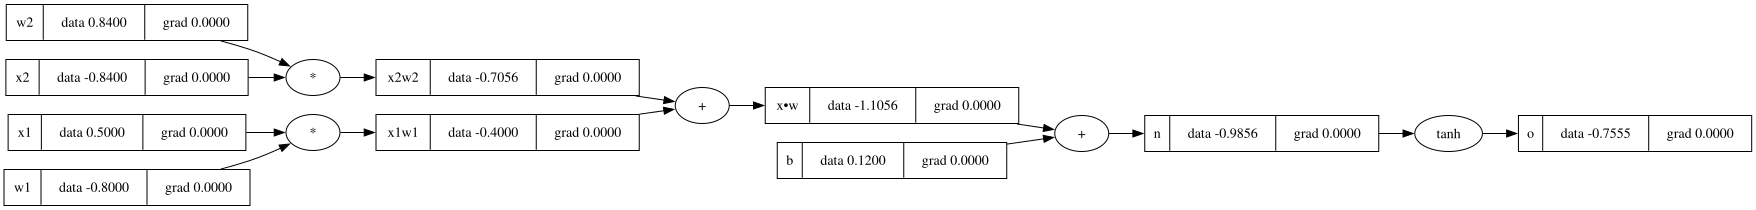

In [ ]:
x1 = Value(0.5, label="x1"); x2 = Value(-0.84, label="x2")
w1 = Value(-0.8, label="w1"); w2 = Value(0.84, label="w2")
b = Value(0.12, label="b")

############# FORWARD PASS ###############

x1w1 = x1*w1; x1w1.label = "x1w1"
x2w2 = x2*w2; x2w2.label = "x2w2"
_sum = x1w1 + x2w2; _sum.label = "x•w"
n = _sum + b; n.label = "n"
o = n.tanh(); o.label = "o"

draw_dot(o)

o = tanh(x•w + b)

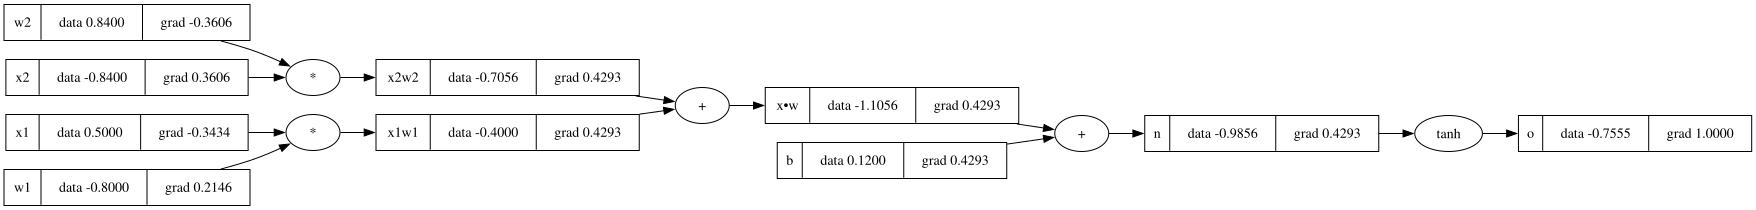

In [34]:
# manually backprop
o.grad = 1 # do/do

n.grad = 1 - o.data**2 # do/dn

b.grad = n.grad * 1 # do/dn * dn/db 

_sum.grad = n.grad * 1 # do/dn * dn/d_sum

x1w1.grad = _sum.grad * 1 # do/dn * dn/d_sum * d_sum/dx1w1
x2w2.grad = _sum.grad * 1 # do/dn * dn/d_sum * d_sum/dx2w2

w1.grad = x1w1.grad * x1.data # do/dn * dn/d_sum * d_sum/dx1w1 * dx1w1/dw1
w2.grad = x2w2.grad * x2.data # do/dn * dn/d_sum * d_sum/dx2w2 * dx2w2/dw2

# (unused)
x1.grad = x1w1.grad * w1.data # do/dn * dn/d_sum * d_sum/dx1w1 * dx1w1/dx1
x2.grad = x2w2.grad * w2.data # do/dn * dn/d_sum * d_sum/dx2w2 * dx2w2/dx2

draw_dot(o)


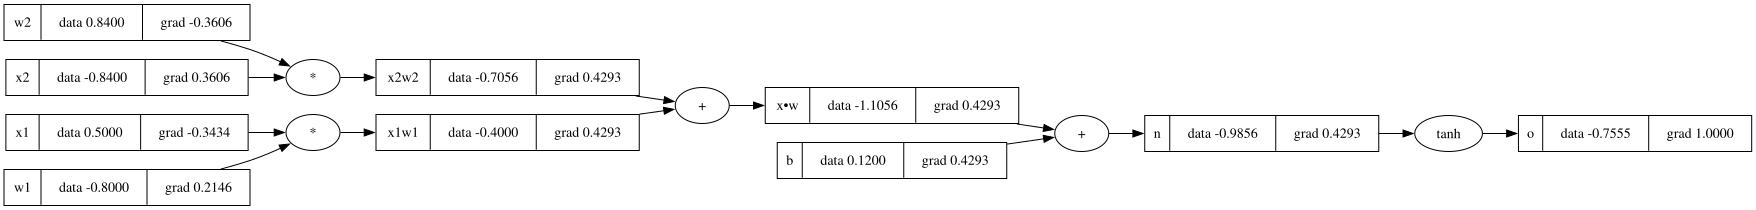

In [35]:
o.backward()
draw_dot(o)